### Project 2

1.   Identify a large 2-node network dataset—you can start with a dataset in a repository.  Your data should meet the criteria that it consists of ties between and not within two (or more) distinct groups.
2.   Reduce the size of the network using a method such as the island method described in chapter 4 of social network analysis.
3.   What can you infer about each of the distinct groups?

You may work in a small group on the project. Your code and analysis should be delivered in an IPython Notebook by end of day Monday


#### Introduction

The goal of this project is to analyze relationships between music listeners and artists using two-mode network analysis. The project uses the HetRec 2011 Last.fm dataset, which contains 92,834 user–artist relationships. Each row represents a connection between a user and an artist, and the weight column records the number of times the user listened to that artist.

The dataset contains two distinct groups: users and artists, with connections occurring between the groups. By representing users and artists as nodes and listening relationships as weighted edges, this project examines patterns in listening activity. The network is then reduced using the island method to focus on stronger listening relationships and draw conclusions about user behavior, artist popularity, and the connections between the two groups.

#### Install and import the tools

I import the Python libraries needed to download, process, analyze, and visualize the Last.fm dataset. Pandas and NumPy support data manipulation, Matplotlib and Seaborn create visualizations, Requests downloads the dataset, and itertools helps work with combinations.

In [ ]:
import networkx as nx
import requests
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from io import BytesIO

### Download and load the dataset

In this section, I download the HetRec 2011 Last.fm dataset from the GroupLens repository and load the user–artist relationships into a pandas dataframe. The resulting dataframe contains 92,834 rows and three columns: userID, artistID, and weight. Each row represents a connection between a user and an artist, and the weight indicates the number of times the user listened to that artist. For example, the first row shows that user 2 listened to artist 51 a total of 13,883 times.

This dataset provides the foundation for constructing a two-mode network in which users and artists form two distinct groups of nodes. The listening relationships between them will be represented as edges, with the listening counts stored as edge weights. These weights will later help reduce the network using an island method and identify meaningful patterns in listening behavior and artist popularity.

In [ ]:
url = (
    "https://files.grouplens.org/datasets/"
    "hetrec2011/hetrec2011-lastfm-2k.zip")

response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    print(z.namelist())

    with z.open("user_artists.dat") as f:
        edges_df = pd.read_csv(f, sep="\t")

print("Shape:", edges_df.shape)
display(edges_df.head())

['user_friends.dat', 'user_taggedartists.dat', 'user_taggedartists-timestamps.dat', 'artists.dat', 'readme.txt', 'tags.dat', 'user_artists.dat']
Shape: (92834, 3)


,userID,artistID,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


#### Load and Merge Artist Information

In this section, I load the artist metadata from the HetRec 2011 Last.fm dataset and merge it with the user listening data. The original dataset identifies artists using numerical IDs, which can make the results difficult to interpret. The artist metadata contains the corresponding artist names, allowing these IDs to be matched with recognizable names. I preserve all listening relationships while adding the corresponding artist names where a match exists. The validate="many_to_one" argument also checks that each artist ID corresponds to no more than one artist record.

Adding artist names will make it easier to interpret the results of the network analysis, particularly when identifying the most connected or frequently listened-to artists. The artist metadata contains 17,632 rows and four columns: id, name, url, and pictureURL. These columns provide artist identifiers, names, and links to artist pages and pictures. After renaming the identifier and name columns, I merged the artist metadata with the user listening data using artistID.

The merged dataset contains 92,834 rows and four columns: userID, artistID, weight, and artist_name. The number of rows remains unchanged, indicating that the merge preserved all listening relationships. The verification checks also show that there are no missing artist names and that all 17,632 unique artists in the listening data have matching names in the metadata. Adding these names makes the dataset easier to interpret and will help identify artists when examining the network's structure and results.

In [ ]:
# Load the artist metadata
with zipfile.ZipFile(BytesIO(response.content)) as z:
    artists_df = pd.read_csv(
        z.open("artists.dat"),
        sep="\t")

print("Artists table shape:", artists_df.shape)
print("Columns:", artists_df.columns.tolist())

display(artists_df.head(10))

# Rename metadata columns
artists_df = artists_df.rename(columns={
    "id": "artistID",
    "name": "artist_name"})

# Merge artist names into the user–artist relationships
edges_named = edges_df.merge(
    artists_df[["artistID", "artist_name"]],
    on="artistID",
    how="left",
    validate="many_to_one")

# Inspect the merged dataset
print("Merged dataset shape:", edges_named.shape)
display(edges_named.head(10))

# Count artist relationships without a matching name
missing_artist_names = edges_named["artist_name"].isna().sum()

print("Relationships without artist names:", missing_artist_names)
print(
    "Unique artists in listening data:",
    edges_df["artistID"].nunique())
print(
    "Unique artists with matched names:",
    edges_named.loc[
        edges_named["artist_name"].notna(), "artistID"
    ].nunique())

Artists table shape: (17632, 4)
Columns: ['id', 'name', 'url', 'pictureURL']


,id,name,url,pictureURL
0,1,MALICE MIZER,http://www.last.fm/music/MALICE+MIZER,http://userserve-ak.last.fm/serve/252/10808.jpg
1,2,Diary of Dreams,http://www.last.fm/music/Diary+of+Dreams,http://userserve-ak.last.fm/serve/252/3052066.jpg
2,3,Carpathian Forest,http://www.last.fm/music/Carpathian+Forest,http://userserve-ak.last.fm/serve/252/40222717...
3,4,Moi dix Mois,http://www.last.fm/music/Moi+dix+Mois,http://userserve-ak.last.fm/serve/252/54697835...
4,5,Bella Morte,http://www.last.fm/music/Bella+Morte,http://userserve-ak.last.fm/serve/252/14789013...
5,6,Moonspell,http://www.last.fm/music/Moonspell,http://userserve-ak.last.fm/serve/252/2181591.jpg
6,7,Marilyn Manson,http://www.last.fm/music/Marilyn+Manson,http://userserve-ak.last.fm/serve/252/2558217.jpg
7,8,DIR EN GREY,http://www.last.fm/music/DIR+EN+GREY,http://userserve-ak.last.fm/serve/252/46968835...
8,9,Combichrist,http://www.last.fm/music/Combichrist,http://userserve-ak.last.fm/serve/252/51273485...
9,10,Grendel,http://www.last.fm/music/Grendel,http://userserve-ak.last.fm/serve/252/5872875.jpg


Merged dataset shape: (92834, 4)


,userID,artistID,weight,artist_name
0,2,51,13883,Duran Duran
1,2,52,11690,Morcheeba
2,2,53,11351,Air
3,2,54,10300,Hooverphonic
4,2,55,8983,Kylie Minogue
5,2,56,6152,Daft Punk
6,2,57,5955,Thievery Corporation
7,2,58,4616,Goldfrapp
8,2,59,4337,New Order
9,2,60,4147,Matt Bianco


Relationships without artist names: 0
Unique artists in listening data: 17632
Unique artists with matched names: 17632


#### Inspecting and Validating the Dataset

In this section, I inspect and validate the merged dataset to ensure that it is complete, consistent, and ready for two-mode network analysis. Before constructing the network, it is important to check for missing values, duplicate relationships, and appropriate data types. I also determine the number of unique users and artists to establish the size of each group in the network.

The merged dataset contains 92,834 user–artist relationships and four columns: userID, artistID, weight, and artist_name. The three numerical columns are stored as integers, while artist_name is stored as a text column. These data types are appropriate for identifying users and artists, representing listening counts, and displaying artist names.

The missing-value check shows that there are no missing values in any of the four columns. Also, the dataset contains no duplicate rows and no duplicate user–artist pairs. This means each recorded user–artist relationship appears only once in the dataset, allowing each row to be represented as a separate edge in the network without needing to resolve repeated relationships.

The dataset contains 1,892 unique users and 17,632 unique artists connected through 92,834 listening relationships. These results establish the sizes of the two distinct groups that will form the bipartite network. The validation checks indicate that the dataset is complete and structurally suitable for constructing the two-mode network.

In [ ]:
# Inspect the dataset and data types

display(edges_named.head())
# Shape
print("Dataset shape:", edges_named.shape)
# column names, data types, and non-null counts
edges_named.info()
# Summary statistics for numerical columns
display(edges_named[["userID", "artistID", "weight"]].describe())

# Missingness
print("Missing values per column:")
print(edges_named.isnull().sum())
print("\nTotal missing values:", edges_named.isnull().sum().sum())

# Duplicate rows and user–artist pairs
# Check for completely duplicated rows
print("Duplicate rows:", edges_named.duplicated().sum())

# Repeated user–artist relationships
duplicate_pairs = edges_named.duplicated(
    subset=["userID", "artistID"]
).sum()

print("Duplicate user–artist pairs:", duplicate_pairs)

#Count unique users and artists
num_users = edges_named["userID"].nunique()
num_artists = edges_named["artistID"].nunique()
num_relationships = len(edges_named)

print("Unique users:", num_users)
print("Unique artists:", num_artists)
print("Total listening relationships:", num_relationships)

,userID,artistID,weight,artist_name
0,2,51,13883,Duran Duran
1,2,52,11690,Morcheeba
2,2,53,11351,Air
3,2,54,10300,Hooverphonic
4,2,55,8983,Kylie Minogue


Dataset shape: (92834, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92834 entries, 0 to 92833
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   userID       92834 non-null  int64 
 1   artistID     92834 non-null  int64 
 2   weight       92834 non-null  int64 
 3   artist_name  92834 non-null  object
dtypes: int64(3), object(1)
memory usage: 2.8+ MB


,userID,artistID,weight
count,92834.000000,92834.000000,92834.00000
mean,1037.010481,3331.123145,745.24393
std,610.870436,4383.590502,3751.32208
min,2.000000,1.000000,1.00000
25%,502.000000,436.000000,107.00000
50%,1029.000000,1246.000000,260.00000
75%,1568.000000,4350.000000,614.00000
max,2100.000000,18745.000000,352698.00000


Missing values per column:
userID         0
artistID       0
weight         0
artist_name    0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Duplicate user–artist pairs: 0
Unique users: 1892
Unique artists: 17632
Total listening relationships: 92834


#### Analyzing the Distribution of Listening Weights

In this section, I examine the distribution of listening weights in the Last.fm dataset using summary statistics and histograms. The weight represents the number of times a user listened to a particular artist and corresponds to the strength of an edge between a user and an artist in the network. Understanding the distribution of these weights is important because the island method will be used to simplify the network by filtering connections according to their weights.

The dataset contains 92,834 user–artist relationships. The minimum listening weight is 1, while the maximum is 352,698. The mean weight is approximately 745.24, and the median is 260. The standard deviation is approximately 3,751.32, indicating substantial variation in listening weights. The 25th percentile is 107, the 75th percentile is 614, the 90th percentile is 1,387, the 95th percentile is 2,328, and the 99th percentile is approximately 7,228. These statistics show that most user–artist relationships have relatively low listening weights, while a small proportion have considerably higher values.

The first histogram, titled Distribution of User–Artist Listening Weights, shows a strongly right-skewed distribution. Most relationships are concentrated near the lower end of the listening-count range, making the smaller values difficult to distinguish because the horizontal axis extends to the maximum weight of 352,698. A small number of relationships have exceptionally high listening counts, creating a long right tail. This pattern is also reflected in the mean being considerably higher than the median.

The second histogram uses a logarithmic scale on the horizontal axis to display the wide range of listening weights. This makes it easier to compare values across different orders of magnitude, from individual listens to relationships with thousands or even hundreds of thousands of listens. However, the distribution remains heavily concentrated in the lower-weight range, illustrating how common weaker listening relationships are compared with extremely high-weight connections.

The third histogram, Distribution of Listening Tie Strengths, displays the base-10 logarithm of the listening weights. This transformation spreads out the lower values and compresses the higher ones, making the overall distribution easier to examine. The histogram shows a peak around log10(weight) values of approximately 2.5–2.7, corresponding to listening weights of roughly 316–501. The distribution tapers off on both sides, although a longer tail extends toward higher values. This visualization provides a clearer view of the variation in listening tie strengths than the original histogram.

The validation checks also confirm that all 92,834 listening weights are positive whole numbers, with no zero or negative values and no non-integer values. Therefore, the weight data meets these basic consistency checks and can be used in the subsequent network analysis.

Overall, the results demonstrate that listening weights are highly unevenly distributed across user–artist relationships. Most connections have relatively low weights, while a small number have exceptionally high weights. This is important for the island method because applying different weight thresholds may change the number of edges retained and the structure of the resulting network. In the next stage, I will compare possible thresholds to identify an appropriate balance between reducing the network's complexity and preserving meaningful connections between users and artists.

Minimum weight: 1
Maximum weight: 352698
Mean weight: 745.2439300256372
Median weight: 260.0
Standard deviation: 3751.322080387676


,weight
0.00,1.00
0.25,107.00
0.50,260.00
0.75,614.00
0.90,1387.00
0.95,2328.00
0.99,7228.01
1.00,352698.00


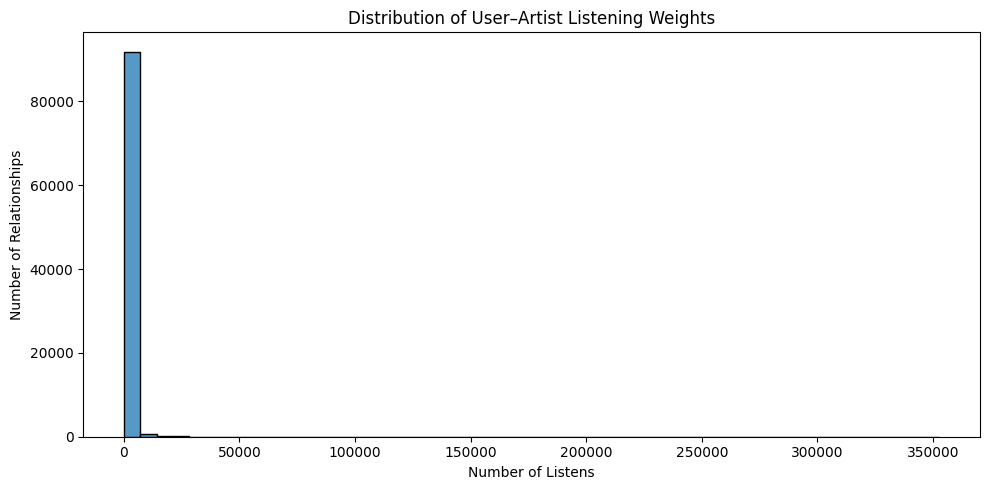

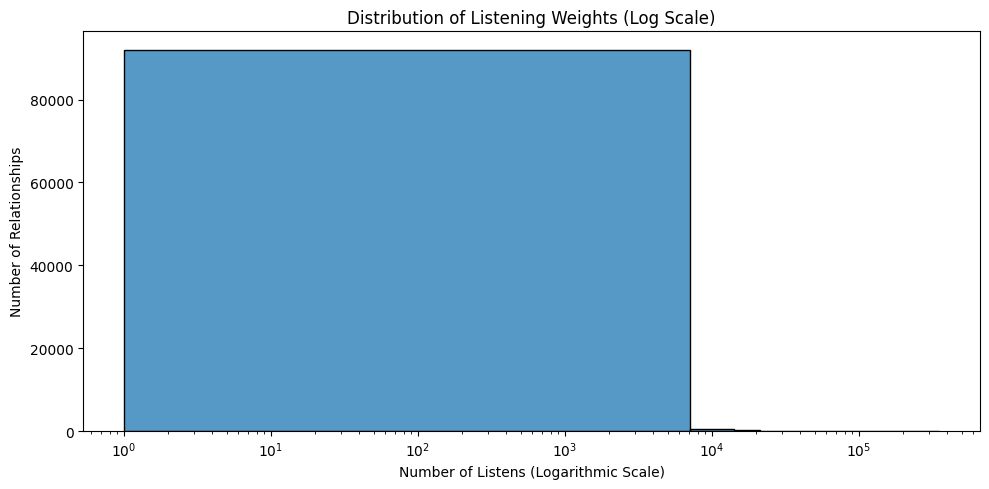

Zero or negative weights: 0
Non-integer weights: 0
count     92834.00000
mean        745.24393
std        3751.32208
min           1.00000
25%         107.00000
50%         260.00000
75%         614.00000
90%        1387.00000
95%        2328.00000
99%        7228.01000
max      352698.00000
Name: weight, dtype: float64


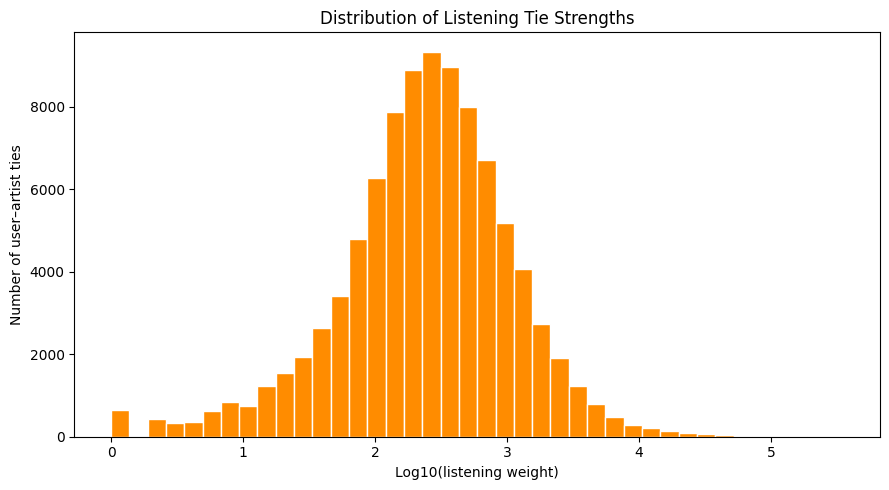

In [ ]:
#Examine listening-weight distributions
# Summary statistics for listening counts
print("Minimum weight:", edges_named["weight"].min())
print("Maximum weight:", edges_named["weight"].max())
print("Mean weight:", edges_named["weight"].mean())
print("Median weight:", edges_named["weight"].median())
print("Standard deviation:", edges_named["weight"].std())

# Selected percentiles
display(
    edges_named["weight"].quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
    )
)

# Visualize the distribution of listening weights
plt.figure(figsize=(10, 5))
sns.histplot(data=edges_named, x="weight", bins=50)

plt.title("Distribution of User–Artist Listening Weights")
plt.xlabel("Number of Listens")
plt.ylabel("Number of Relationships")

plt.tight_layout()
plt.show()

#Visualize the distribution using a logarithmic scale

plt.figure(figsize=(10, 5))

sns.histplot(data=edges_named, x="weight", bins=50)
plt.xscale("log")

plt.title("Distribution of Listening Weights (Log Scale)")
plt.xlabel("Number of Listens (Logarithmic Scale)")
plt.ylabel("Number of Relationships")

plt.tight_layout()
plt.show()

# Check whether listening weights are valid

print("Zero or negative weights:", (edges_named["weight"] <= 0).sum())
print("Non-integer weights:", (edges_named["weight"] % 1 != 0).sum())

print(edges_named["weight"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

plt.figure(figsize=(9, 5))

plt.hist(
    np.log10(edges_named["weight"]),
    bins=40,
    color="darkorange",
    edgecolor="white")

plt.xlabel("Log10(listening weight)")
plt.ylabel("Number of user–artist ties")
plt.title("Distribution of Listening Tie Strengths")
plt.tight_layout()
plt.show()

#### Exploring the Most-Listened-to Artists

In this section, I identify and visualize the 15 artists with the highest total listening counts in the Last.fm dataset. The purpose of this analysis is to establish a baseline understanding of artist popularity before constructing and reducing the two-mode network. Identifying the most-listened-to artists provides an initial picture of listening activity and helps determine which artists account for the largest totals. Comparing total plays with the number of unique listeners also helps distinguish artists who receive many plays from those who attract a larger audience.

The bar chart shows that Britney Spears ranks first, with approximately 2.4 million recorded plays, substantially exceeding the other artists. Depeche Mode and Lady Gaga follow, with approximately 1.3 million plays each. Other artists in the top 15 include Christina Aguilera, Paramore, Madonna, Rihanna, Beyoncé, Glee Cast, Evanescence, Taylor Swift, Avril Lavigne, and Katy Perry.

Overall, the chart illustrates that total listening activity is unevenly distributed among the most-listened-to artists. Britney Spears stands out as particularly prominent in terms of total plays. However, these totals do not necessarily indicate how many different users listen to each artist, since high totals may result from repeated listening by a smaller group of users. The subsequent two-mode network analysis will provide a more detailed understanding of how users connect to artists and how these relationships change when the network is reduced using an island method.

,artistID,artist_name,total_plays,number_of_listeners
283,289,Britney Spears,2393140,522
66,72,Depeche Mode,1301308,282
83,89,Lady Gaga,1291387,611
286,292,Christina Aguilera,1058405,407
492,498,Paramore,963449,399
61,67,Madonna,921198,429
282,288,Rihanna,905423,484
695,701,Shakira,688529,319
221,227,The Beatles,662116,480
294,300,Katy Perry,532545,473


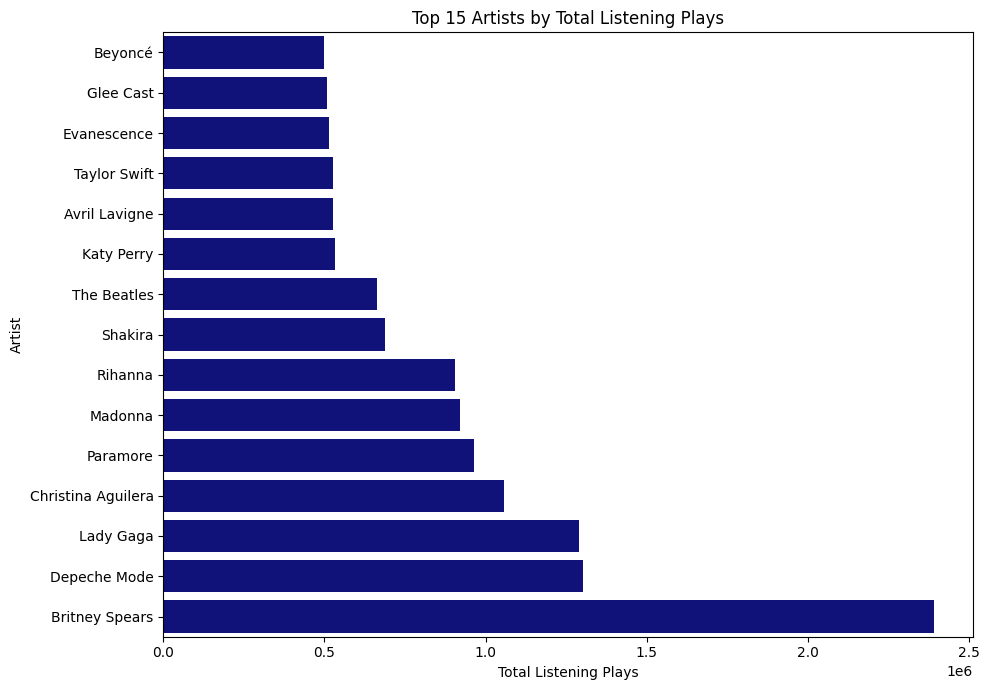

In [ ]:
# Find the most-listened-to artists
top_artists = (
    edges_named.groupby(
        ["artistID", "artist_name"], as_index=False
    )
    .agg(
        total_plays=("weight", "sum"),
        number_of_listeners=("userID", "nunique")
    )
    .sort_values("total_plays", ascending=False)
)

display(top_artists.head(15))

# Prepare the top 15 artists for visualization
top15 = top_artists.head(15).sort_values("total_plays")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top15,
    x="total_plays",
    y="artist_name",
    color="darkblue"
)

plt.xlabel("Total Listening Plays")
plt.ylabel("Artist")
plt.title("Top 15 Artists by Total Listening Plays")
plt.tight_layout()
plt.show()

### Artist Audience Size vs. Listening Intensity

This code creates a scatter plot to explore the relationship between the number of unique listeners an artist has and their total listening plays in order to compare popularity with listening intensity. Each point represents an artist, allowing you to compare how many people listen to an artist with how often their music is played. The goal is to understand whether artists with larger audiences also tend to receive more total plays.

The horizontal axis represents the number of unique listeners, while the vertical axis represents total listening plays. Artists positioned further to the right have more listeners, while those higher up have more total plays. This comparison can help identify artists with large audiences and artists whose music may be played repeatedly by a smaller group of listeners.

The scatter plot shows a positive relationship between the number of unique listeners and total listening plays. In general, artists with larger audiences tend to accumulate more total plays. However, the relationship is not perfectly consistent, as artists with similar audience sizes can have noticeably different numbers of plays.

Most artists are clustered near the lower-left corner of the plot, indicating that they have relatively few unique listeners and lower total play counts. As the number of listeners increases, the spread of total plays becomes wider, suggesting that listening intensity varies considerably among artists.

There are also several outliers, including artists with approximately 300 listeners and 1.3 million plays, as well as an artist with around 520 listeners and 2.4 million plays. These artists have exceptionally high play counts compared with most others in the dataset. This may indicate frequent repeat listening, highly engaged audiences, or other factors that increase total plays.

The plot suggests that audience size contributes to total listening plays, but it does not fully explain listening intensity. Some artists may generate substantially more plays than expected for their audience size, potentially reflecting stronger listener engagement or repeated listening. To investigate this further, the ratio of total plays to unique listeners could be calculated for each artist. This would help identify artists whose audiences listen to their music most frequently, rather than simply identifying artists with the largest audiences.

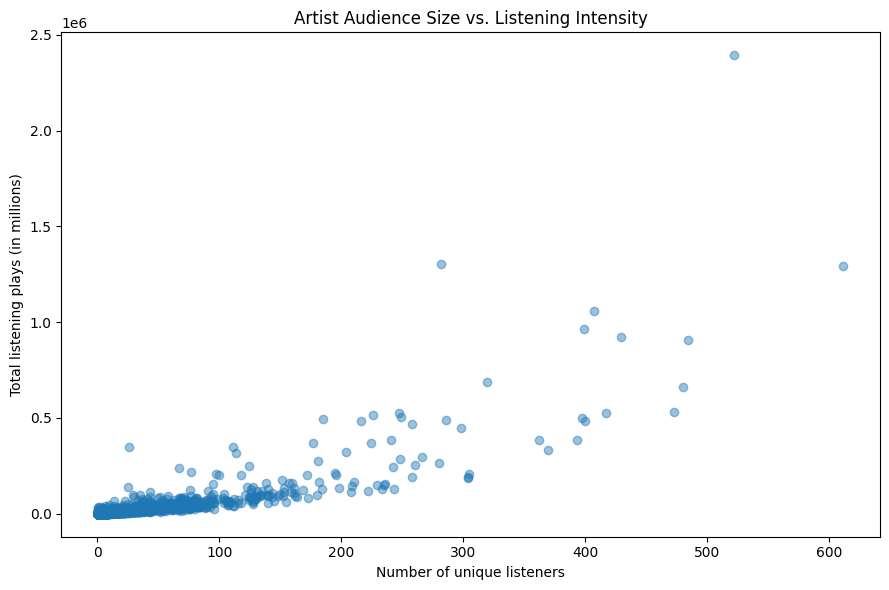

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    top_artists["number_of_listeners"],
    top_artists["total_plays"],
    alpha=0.45)

plt.xlabel("Number of unique listeners")
plt.ylabel("Total listening plays (in millions)")
plt.title("Artist Audience Size vs. Listening Intensity")
plt.tight_layout()
plt.show()


#### Constructing the Two-Mode Network

In this section, I construct a two-mode network - the network consists of two distinct groups of nodes: users and artists. An edge connects a user to an artist when the user has a recorded listening relationship with that artist. The weight of each edge represents the number of times the user listened to the artist.

The purpose of constructing this network is to represent the listening relationships in a form that can be analyzed using social network analysis techniques. By creating a bipartite graph, I can examine the connections between users and artists while preserving the distinction between the two groups. This network will serve as the basis for applying the island method to reduce the network and identify meaningful patterns in listening behavior and artist popularity.

The two-mode network was successfully constructed using NetworkX. The resulting graph contains 19,524 nodes and 92,834 edges. Of these nodes, 1,892 represent users and 17,632 represent artists. Each edge represents a recorded listening relationship between a user and an artist, with the edge weight indicating the number of times the user listened to that artist.

To verify the network's structure, I checked that every edge connects nodes from different groups. The verification returned True, confirming that all edges connect users to artists rather than connecting users to other users or artists to other artists. I also inspected an example edge between user 2 and artist 51, which has a weight of 13,883, matching the original dataset.

These results confirm that the graph correctly represents the dataset as a bipartite network. The network provides a foundation for the next stage of the project: reducing its size using the island method to focus on stronger listening relationships and make the network easier to interpret.

In [ ]:
# Create an empty undirected graph
B = nx.Graph()

# Add user nodes
users = edges_named["userID"].unique()

B.add_nodes_from(
    [f"user_{user}" for user in users],
    bipartite=0,
    node_type="user"
)

# Add artist nodes
artists = edges_named["artistID"].unique()

artist_names = (
    edges_named[["artistID", "artist_name"]]
    .drop_duplicates(subset="artistID")
    .set_index("artistID")["artist_name"]
    .to_dict()
)

B.add_nodes_from(
    [
        (f"artist_{artist}", {
            "bipartite": 1,
            "node_type": "artist",
            "artist_name": artist_names[artist]
        })
        for artist in artists
    ]
)

# Add user–artist edges with listening weights
B.add_weighted_edges_from(
    [
        (f"user_{row.userID}",
         f"artist_{row.artistID}",
         row.weight)
        for row in edges_named.itertuples(index=False)
    ],
    weight="weight"
)

print("Number of nodes:", B.number_of_nodes())
print("Number of edges:", B.number_of_edges())

# verify
# Count nodes belonging to each group
user_nodes = [
    n for n, data in B.nodes(data=True)
    if data["node_type"] == "user"
]

artist_nodes = [
    n for n, data in B.nodes(data=True)
    if data["node_type"] == "artist"
]

print("User nodes:", len(user_nodes))
print("Artist nodes:", len(artist_nodes))
print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())

# Verify that every edge connects a user to an artist
valid_edges = all(
    B.nodes[u]["node_type"] != B.nodes[v]["node_type"]
    for u, v in B.edges()
)

print("All edges connect users to artists:", valid_edges)

# Inspect an example edge and its attributes
u, v = next(iter(B.edges()))

print("Example edge:", u, "<->", v)
print("Edge attributes:", B[u][v])

Number of nodes: 19524
Number of edges: 92834
User nodes: 1892
Artist nodes: 17632
Total nodes: 19524
Total edges: 92834
All edges connect users to artists: True
Example edge: user_2 <-> artist_51
Edge attributes: {'weight': 13883}


#### Reducing the Network Using the Island Method

Here, I reduce the size of the original two-mode user–artist network using an island method based on listening weights. The original network contains 19,524 nodes and 92,834 edges, making it difficult to examine individual relationships and identify meaningful structural patterns in its full form.

Each edge represents a user–artist relationship, and its weight indicates the number of times a user listened to a particular artist. To simplify the network, I apply five minimum listening-weight thresholds based on the 50th, 75th, 90th, 95th, and 99th percentiles of the listening-weight distribution. At each threshold, I retain only relationships whose listening counts meet or exceed the cutoff. I then examine the remaining nodes and edges, the number of connected components, and the size of the largest connected component, also referred to as the largest island.

The results show that increasing the minimum listening-weight threshold substantially reduces the network. At a threshold of 260 listens, the network contains 46,420 edges and 11,316 nodes. At the highest threshold of 7,228 listens, only 929 edges and 850 nodes remain. This demonstrates how filtering out lower-weight relationships produces a smaller network that emphasizes more frequent listening activity.

Figure interpretation. The left plot, Edges Remaining, shows a steep decline in the number of edges as the minimum listening-weight threshold increases. The reduction is especially pronounced at the lower thresholds, indicating that many user–artist relationships are removed as the cutoff becomes more restrictive. The middle plot, Connected Components, shows the opposite trend: the number of connected components increases from 21 at a threshold of 260 to 79 at a threshold of 7,228. This occurs because removing edges can disconnect previously connected users and artists, splitting the network into smaller groups or isolated nodes. The right plot, Largest Island Size, shows that the largest connected component decreases from 11,236 nodes at the lowest threshold to 653 nodes at the highest threshold. Together, these plots illustrate the trade-off between reducing network size and preserving connectivity.

I selected a threshold of 1,387 listens, corresponding to the 90th-percentile cutoff used in this analysis, as the working threshold for further investigation. At this cutoff, the network contains 4,116 nodes and 9,288 edges, compared with the original 19,524 nodes and 92,834 edges. The remaining network consists of 1,293 users and 2,823 artists, with 60 connected components. The largest island contains 3,989 nodes and 9,220 edges. Thus, approximately 97% of the remaining nodes and 99% of the remaining edges belong to the largest connected component, indicating that the filtered network is still dominated by one large connected group.

I then examined the artists with the greatest numbers of user connections within this largest island. Britney Spears ranked first with 217 listeners, followed by Lady Gaga with 181. Rihanna and Christina Aguilera each had 129 listeners, while Madonna had 117. The Beatles had 105 listeners, followed by Depeche Mode with 95 and Paramore with 92. These results identify artists who are connected to many users within the reduced network. However, these counts reflect the number of user connections that survive the filtering process, rather than the artists' total audiences across the original network.

The island method provides a way to focus on stronger recorded listening relationships while retaining a network structure suitable for further analysis. The threshold of 1,387 listens substantially reduces the network while preserving a large connected component containing most of its remaining nodes and edges. Nevertheless, the threshold is an analytical choice rather than a definitive boundary between important and unimportant relationships. The results reflect listening activity recorded in the dataset and should not be interpreted as direct measures of users' favorite artists, musical preferences, or satisfaction.

,threshold,nodes,edges,users,artists,components,largest_island_nodes
0,260,11316,46420,1735,9581,21,11236
1,614,7155,23221,1574,5581,35,7054
2,1387,4116,9288,1293,2823,60,3989
3,2328,2698,4643,1020,1678,67,2543
4,7228,850,929,456,394,79,653


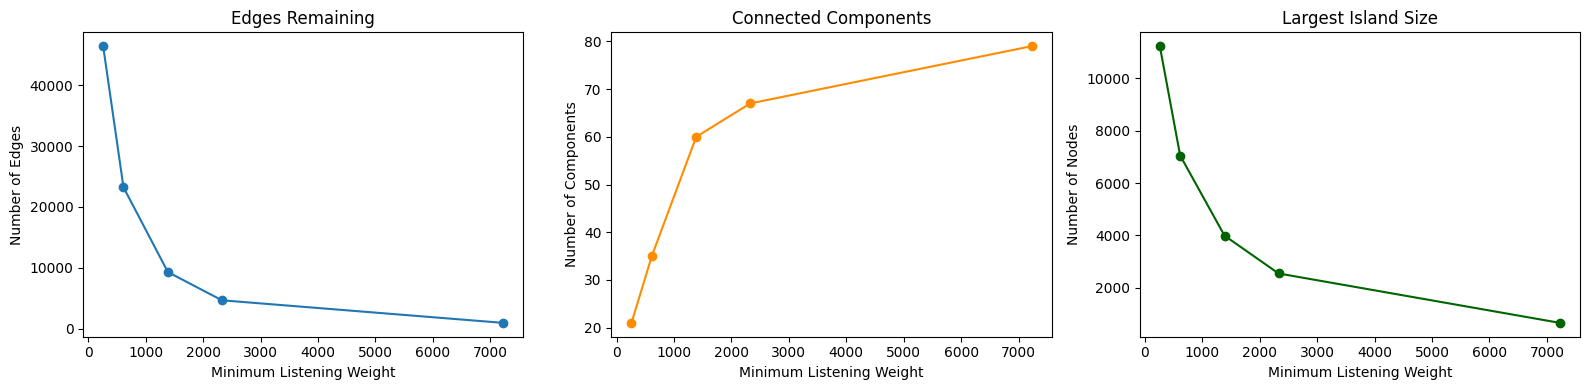

Chosen threshold: 1387
Nodes remaining: 4116
Edges remaining: 9288
Connected components: 60
Largest island nodes: 3989
Largest island edges: 9220


,artistID,artist,listeners_in_island
46,289,Britney Spears,217
38,89,Lady Gaga,181
45,288,Rihanna,129
49,292,Christina Aguilera,129
16,67,Madonna,117
176,227,The Beatles,105
21,72,Depeche Mode,95
97,498,Paramore,92
57,300,Katy Perry,91
148,190,Muse,72


In [ ]:
# Compare possible thresholds

# Generate candidate thresholds from the weight distribution
quantiles = [0.50, 0.75, 0.90, 0.95, 0.99]

thresholds = sorted(set(
    int(edges_named["weight"].quantile(q))
    for q in quantiles
))

results = []

for threshold in thresholds:
    filtered = edges_named[
        edges_named["weight"] >= threshold
    ]

    # Build the filtered two-mode network
    B_test = nx.Graph()

    for row in filtered.itertuples(index=False):
        user_node = f"user::{row.userID}"
        artist_node = f"artist::{row.artistID}"

        B_test.add_node(user_node, node_type="user")
        B_test.add_node(
            artist_node,
            node_type="artist",
            artist_name=row.artist_name
        )

        B_test.add_edge(
            user_node,
            artist_node,
            weight=row.weight
        )

    # Identify connected components
    components = sorted(
        nx.connected_components(B_test),
        key=len,
        reverse=True
    )

    results.append({
        "threshold": threshold,
        "nodes": B_test.number_of_nodes(),
        "edges": B_test.number_of_edges(),
        "users": sum(
            d["node_type"] == "user"
            for _, d in B_test.nodes(data=True)
        ),
        "artists": sum(
            d["node_type"] == "artist"
            for _, d in B_test.nodes(data=True)
        ),
        "components": len(components),
        "largest_island_nodes": (
            len(components[0]) if components else 0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)


# Plot the effect of each threshold

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    threshold_results["threshold"],
    threshold_results["edges"],
    marker="o"
)
axes[0].set_title("Edges Remaining")
axes[0].set_xlabel("Minimum Listening Weight")
axes[0].set_ylabel("Number of Edges")

axes[1].plot(
    threshold_results["threshold"],
    threshold_results["components"],
    marker="o",
    color="darkorange"
)
axes[1].set_title("Connected Components")
axes[1].set_xlabel("Minimum Listening Weight")
axes[1].set_ylabel("Number of Components")

axes[2].plot(
    threshold_results["threshold"],
    threshold_results["largest_island_nodes"],
    marker="o",
    color="darkgreen"
)
axes[2].set_title("Largest Island Size")
axes[2].set_xlabel("Minimum Listening Weight")
axes[2].set_ylabel("Number of Nodes")

plt.tight_layout()
plt.show()

# Choose a threshold and examine the largest island

# Temporary starting point: 90th-percentile threshold
chosen_threshold = int(edges_named["weight"].quantile(0.90))

filtered = edges_named[
    edges_named["weight"] >= chosen_threshold
]

B_reduced = nx.Graph()

for row in filtered.itertuples(index=False):
    user_node = f"user::{row.userID}"
    artist_node = f"artist::{row.artistID}"

    B_reduced.add_node(user_node, node_type="user")
    B_reduced.add_node(
        artist_node,
        node_type="artist",
        artist_name=row.artist_name
    )

    B_reduced.add_edge(
        user_node,
        artist_node,
        weight=row.weight
    )

components = sorted(
    nx.connected_components(B_reduced),
    key=len,
    reverse=True
)

print("Chosen threshold:", chosen_threshold)
print("Nodes remaining:", B_reduced.number_of_nodes())
print("Edges remaining:", B_reduced.number_of_edges())
print("Connected components:", len(components))

if components:
    largest_island = B_reduced.subgraph(components[0]).copy()

    print("Largest island nodes:", largest_island.number_of_nodes())
    print("Largest island edges:", largest_island.number_of_edges())

    island_artists = pd.DataFrame([
        {
            "artistID": int(node.split("::")[1]),
            "artist": data["artist_name"],
            "listeners_in_island": largest_island.degree(node)
        }
        for node, data in largest_island.nodes(data=True)
        if data["node_type"] == "artist"
    ]).sort_values(
        "listeners_in_island",
        ascending=False
    )

    display(island_artists.head(15))

### Comparing the Original and Reduced Networks

In this section, I compare the original network with the reduced network to measure the effect of applying the selected listening-weight threshold of 1,387. This comparison shows how many users, artists, nodes, and edges remain after filtering out weaker listening relationships. The purpose is to quantify the reduction and determine whether the resulting network is more manageable for further analysis.

The original network contains 19,524 nodes, consisting of 1,892 users and 17,632 artists, connected by 92,834 edges. After applying the threshold, the reduced network contains 4,116 nodes, including 1,293 users and 2,823 artists, connected by 9,288 edges.

Overall, the reduction removes 15,408 nodes, representing approximately 78.92% of the original nodes. The number of edges decreases by 83,546, or approximately 90.00%. This shows that filtering by listening weight substantially reduces the network while retaining a considerable number of users and artists connected through stronger listening relationships.

The comparison confirms that the selected threshold produces a much smaller network that is easier to examine. The reduced network can now be investigated further to identify connected components and determine which users and artists remain prominent within the strongest listening relationships.

In [ ]:
# original

original_users = edges_named["userID"].nunique()
original_artists = edges_named["artistID"].nunique()
original_nodes = original_users + original_artists

# Reduced network (using your chosen threshold)
chosen_threshold = thresholds[2]  # 90th percentile

filtered = edges_named[
    edges_named["weight"] >= chosen_threshold
]

new_users = filtered["userID"].nunique()
new_artists = filtered["artistID"].nunique()
new_nodes = new_users + new_artists

# Display comparison
comparison = pd.DataFrame({
    "Network": ["Original", "Reduced"],
    "User nodes": [original_users, new_users],
    "Artist nodes": [original_artists, new_artists],
    "Total nodes": [original_nodes, new_nodes],
    "Edges": [len(edges_named), len(filtered)]
})

display(comparison)

print(f"Nodes removed: {original_nodes - new_nodes:,}")
print(
    f"Percentage of nodes removed: "
    f"{100 * (original_nodes - new_nodes) / original_nodes:.2f}%"
)

,Network,User nodes,Artist nodes,Total nodes,Edges
0,Original,1892,17632,19524,92834
1,Reduced,1293,2823,4116,9288


Nodes removed: 15,408
Percentage of nodes removed: 78.92%


#### Analyzing Connected Components and the Largest Island

In this section, I examine the connected components of the reduced network to understand how users and artists remain connected after applying the minimum listening-weight threshold of 1,387. A connected component, also referred to as an island, is a group of nodes in which every node can be reached from every other node through a path of connections. Identifying these components helps reveal whether the stronger listening relationships form one large interconnected network or several smaller, disconnected groups.

The reduced network contains 60 connected components. The largest component contains 3,989 nodes and 9,220 edges, whereas the second- and third-largest components contain only four nodes each. The remaining components are similarly small, with sizes ranging from one to three nodes among the next largest groups. This indicates that the network is highly concentrated in one dominant connected component, while the remaining nodes form small disconnected groups. The largest island contains approximately 96.9% of all 4,116 nodes and 99.3% of all 9,288 edges in the reduced network, demonstrating that nearly all retained relationships belong to the same interconnected structure.

I then examined the artists with the highest numbers of user connections within the largest island. Britney Spears ranks first with 217 user connections, followed by Lady Gaga with 181. Rihanna and Christina Aguilera each have 129 connections, while Madonna has 117. The Beatles and Depeche Mode also have prominent positions, with 105 and 95 connections, respectively. Paramore and Katy Perry follow with 92 and 91 connections.

These results identify artists with the greatest numbers of user connections among the relationships retained in the largest island. Britney Spears and Lady Gaga have particularly high connectivity, suggesting that their music is linked to a comparatively large number of users within this filtered network. The presence of artists such as Rihanna, Christina Aguilera, Madonna, The Beatles, and Depeche Mode further demonstrates that the largest island contains connections involving a diverse range of artists.

Overall, the component analysis shows that filtering the network produces one dominant interconnected group rather than many similarly sized islands. The concentration of almost all remaining edges in the largest component suggests that the threshold of 1,387 listens preserves a cohesive structure for further analysis. Examining artist connectivity within this component also helps identify which artists are connected to the greatest number of users through relationships that meet the selected threshold. However, these results describe connectivity within the reduced network and should not be interpreted as a complete measure of popularity across all Last.fm users or as a direct measure of total listening activity.

In [ ]:
# Build the reduced network
B_reduced = nx.Graph()

for row in filtered.itertuples(index=False):
    user_node = f"user::{row.userID}"
    artist_node = f"artist::{row.artistID}"

    B_reduced.add_node(user_node, node_type="user")
    B_reduced.add_node(
        artist_node,
        node_type="artist",
        artist_name=row.artist_name
    )

    B_reduced.add_edge(
        user_node,
        artist_node,
        weight=row.weight
    )

# Identify connected components (islands)
components = sorted(
    nx.connected_components(B_reduced),
    key=len,
    reverse=True
)

print("Number of islands:", len(components))
print("Largest island sizes:", [len(c) for c in components[:10]])

# Extract the largest island
largest_island = B_reduced.subgraph(components[0]).copy()

print("Largest island nodes:", largest_island.number_of_nodes())
print("Largest island edges:", largest_island.number_of_edges())

# Find artists with the most user connections in the largest island
island_artists = pd.DataFrame([
    {
        "artist": data["artist_name"],
        "user_connections": largest_island.degree(node)
    }
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "artist"
]).sort_values(
    "user_connections",
    ascending=False
)

display(island_artists.head(15))

Number of islands: 60
Largest island sizes: [3989, 4, 4, 3, 3, 3, 3, 3, 2, 2]
Largest island nodes: 3989
Largest island edges: 9220


,artist,user_connections
46,Britney Spears,217
38,Lady Gaga,181
45,Rihanna,129
49,Christina Aguilera,129
16,Madonna,117
176,The Beatles,105
21,Depeche Mode,95
97,Paramore,92
57,Katy Perry,91
148,Muse,72


Analyzing users in the largest island

Analyzing User Connections in the Largest Island

In this section, I examine the users with the highest numbers of artist connections in the largest island of the reduced network. Each connection represents a user–artist relationship whose listening weight meets the selected threshold of 1,387 listens. The purpose is to identify users who maintain strong listening relationships with a wide range of artists and to compare the structure of the user group with the artist group.

The results show that the highest observed number of artist connections is 50, shared by 12 users. These are followed by users with 49 and 48 connections. This indicates that several users maintain strong listening relationships with many different artists within the largest island.

These results suggest that some users have broader patterns of listening activity than others within the reduced network. However, the number of connections measures the number of distinct artists linked to each user, not their total listening volume. Because the network includes only relationships meeting the selected weight threshold and belonging to the largest island, these results do not represent users' complete listening histories.

Overall, the analysis provides insight into the user group by identifying individuals who remain connected to many artists after weaker relationships are removed. Combined with the artist analysis, it helps show how strong listening relationships connect users and artists within the largest component of the network.

In [ ]:
# Identify users with the most artist connections
island_users = pd.DataFrame([
    {
        "userID": int(node.split("::")[1]),
        "artist_connections": largest_island.degree(node)
    }
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "user"
]).sort_values(
    "artist_connections",
    ascending=False
)

display(island_users.head(15))

,userID,artist_connections
71,104,50
255,387,50
468,734,50
1159,1971,50
721,1195,50
1180,2007,50
1175,2000,50
518,831,50
890,1504,50
296,455,50


#### Analyzing Listening Strength Among Users and Artists

In this section, I examine the listening strength of users and artists within the largest island of the reduced network. Listening strength is calculated by summing the weights of a node's connections. Unlike degree, which measures the number of connections a node has, listening strength measures the total recorded listening activity associated with those connections. Comparing these two measures helps determine whether nodes with more connections also accumulate greater listening activity, or whether a smaller number of strong relationships can produce a high listening-strength value.

The results show that Britney Spears has the highest listening strength among artists, with a total of 2,242,053 across 217 user connections. Depeche Mode ranks second with 1,229,904 across 95 connections, followed by Lady Gaga with 1,101,655 across 181 connections. Christina Aguilera, Paramore, Madonna, and Rihanna also rank among the artists with the highest listening strength. These findings indicate that these artists are associated with substantial recorded listening activity within the largest island of the filtered network.

The results also demonstrate that listening strength and the number of connections do not always correspond directly. For example, Shakira has 51 user connections and a listening strength of 579,878, while Rihanna has 129 connections and a listening strength of 747,370. Although Rihanna has more than twice as many connections, her listening strength is not proportionally higher. This illustrates that an artist's listening strength depends on both the number of retained user connections and the listening weights associated with each connection. Artists with fewer connections can still accumulate substantial listening strength when their individual relationships have relatively high weights.

Among users, user 757 has the highest listening strength, at 469,614 across 17 artist connections. User 2000 has a similar listening strength of 468,409 but has 50 artist connections. This comparison suggests that user 757's recorded listening activity is concentrated across fewer retained relationships, whereas user 2000's activity is distributed across a broader set of artists. Similarly, user 2071 has a listening strength of 327,104 across only two artist connections. This indicates that a small number of relationships can account for substantial listening activity when their edge weights are high.

Overall, these results reveal differences in how listening activity is distributed across artists and users. Some artists combine numerous user connections with high cumulative listening strength, while some users achieve high listening-strength values through relatively few artist relationships. The comparison highlights the importance of considering both degree and listening strength when analyzing the network: degree describes the breadth of a node's connections, whereas listening strength captures the total weight of those connections.

However, the analysis is restricted to the largest island of the reduced network, where only user–artist relationships with at least 1,387 recorded listens were retained. Consequently, the reported listening-strength values represent activity within the filtered network rather than users' complete listening histories. The results provide insight into the distribution of recorded listening activity among the strongest retained relationships, but they should not be interpreted as direct measures of preference, loyalty, or overall musical engagement.

In [ ]:
# Calculate total listening strength for each node
strength = dict(largest_island.degree(weight="weight"))

# Combine results
strength_df = pd.DataFrame([
    {
        "node_id": node,
        "node_type": data["node_type"],
        "artist_name": data.get("artist_name"),
        "number_of_connections": largest_island.degree(node),
        "listening_strength": strength[node]
    }
    for node, data in largest_island.nodes(data=True)
])

# Top 10 artists by total listening strength
print("Top 10 artists by listening strength:")

display(
    strength_df[strength_df["node_type"] == "artist"]
    .sort_values("listening_strength", ascending=False)
    [["artist_name", "number_of_connections", "listening_strength"]]
    .head(10)
)

# Top 10 users by total listening strength
print("Top 10 users by listening strength:")

display(
    strength_df[strength_df["node_type"] == "user"]
    .sort_values("listening_strength", ascending=False)
    [["node_id", "number_of_connections", "listening_strength"]]
    .head(10)
)

Top 10 artists by listening strength:


,artist_name,number_of_connections,listening_strength
49,Britney Spears,217,2242053
22,Depeche Mode,95,1229904
39,Lady Gaga,181,1101655
52,Christina Aguilera,129,918646
105,Paramore,92,843576
17,Madonna,117,802738
48,Rihanna,129,747370
277,Shakira,51,579878
206,The Beatles,105,500318
88,Taylor Swift,65,454328


Top 10 users by listening strength:


,node_id,number_of_connections,listening_strength
2035,user::757,17,469614
3799,user::2000,50,468409
2986,user::1418,27,399636
3315,user::1642,6,378019
2568,user::1094,12,361428
3669,user::1942,50,348527
3891,user::2031,50,329980
3942,user::2071,2,327104
1203,user::387,50,322661
1520,user::514,10,308307


#### Interpreting the Network Visualization

The network graph illustrates the relationships between users and the 15 most connected artists within the largest island of the reduced network. Blue nodes represent users, while orange nodes represent artists. The edges connecting these nodes represent user–artist listening relationships with weights of at least 1,387 listens. The visualization provides a closer look at how users are connected to prominent artists within the filtered network.

The graph shows that some artists have connections to many users, consistent with the degree rankings from the earlier analysis. Britney Spears and Lady Gaga are among the most connected artists, alongside Rihanna, Christina Aguilera, and Madonna. Their prominent positions in the network reflect their relatively high numbers of user connections. Other artists, including The Beatles, Depeche Mode, Paramore, Muse, and Radiohead, also appear as important nodes within the selected subnetwork, demonstrating that the largest island includes listening relationships involving artists from different musical styles.

The visualization also illustrates how users may connect to multiple selected artists. Users linked to more than one artist provide connections between those artists' audiences within the network, helping explain how these relationships form part of a larger connected structure. For example, the network contains a dense cluster of artists near the center, with many user nodes and overlapping edges. Other artists, such as The Beatles, Depeche Mode, and Radiohead, appear farther from this central cluster. However, these visual positions are determined by the network layout algorithm and do not necessarily indicate separate communities or dissimilar audiences. Confirming such patterns would require additional analysis of shared neighbors, audience overlap, or community structure.

Overall, the visualization provides a graphical representation of how users connect to prominent artists through strong recorded listening relationships. Combined with the degree and listening-strength analyses, it helps illustrate differences in artist connectivity and the extent to which users connect across the selected artists. However, the graph displays only the 15 most connected artists and the users connected to them, rather than the entire largest island. It should therefore be interpreted as a focused view of the network, not a complete representation of all users and artists in the reduced dataset.

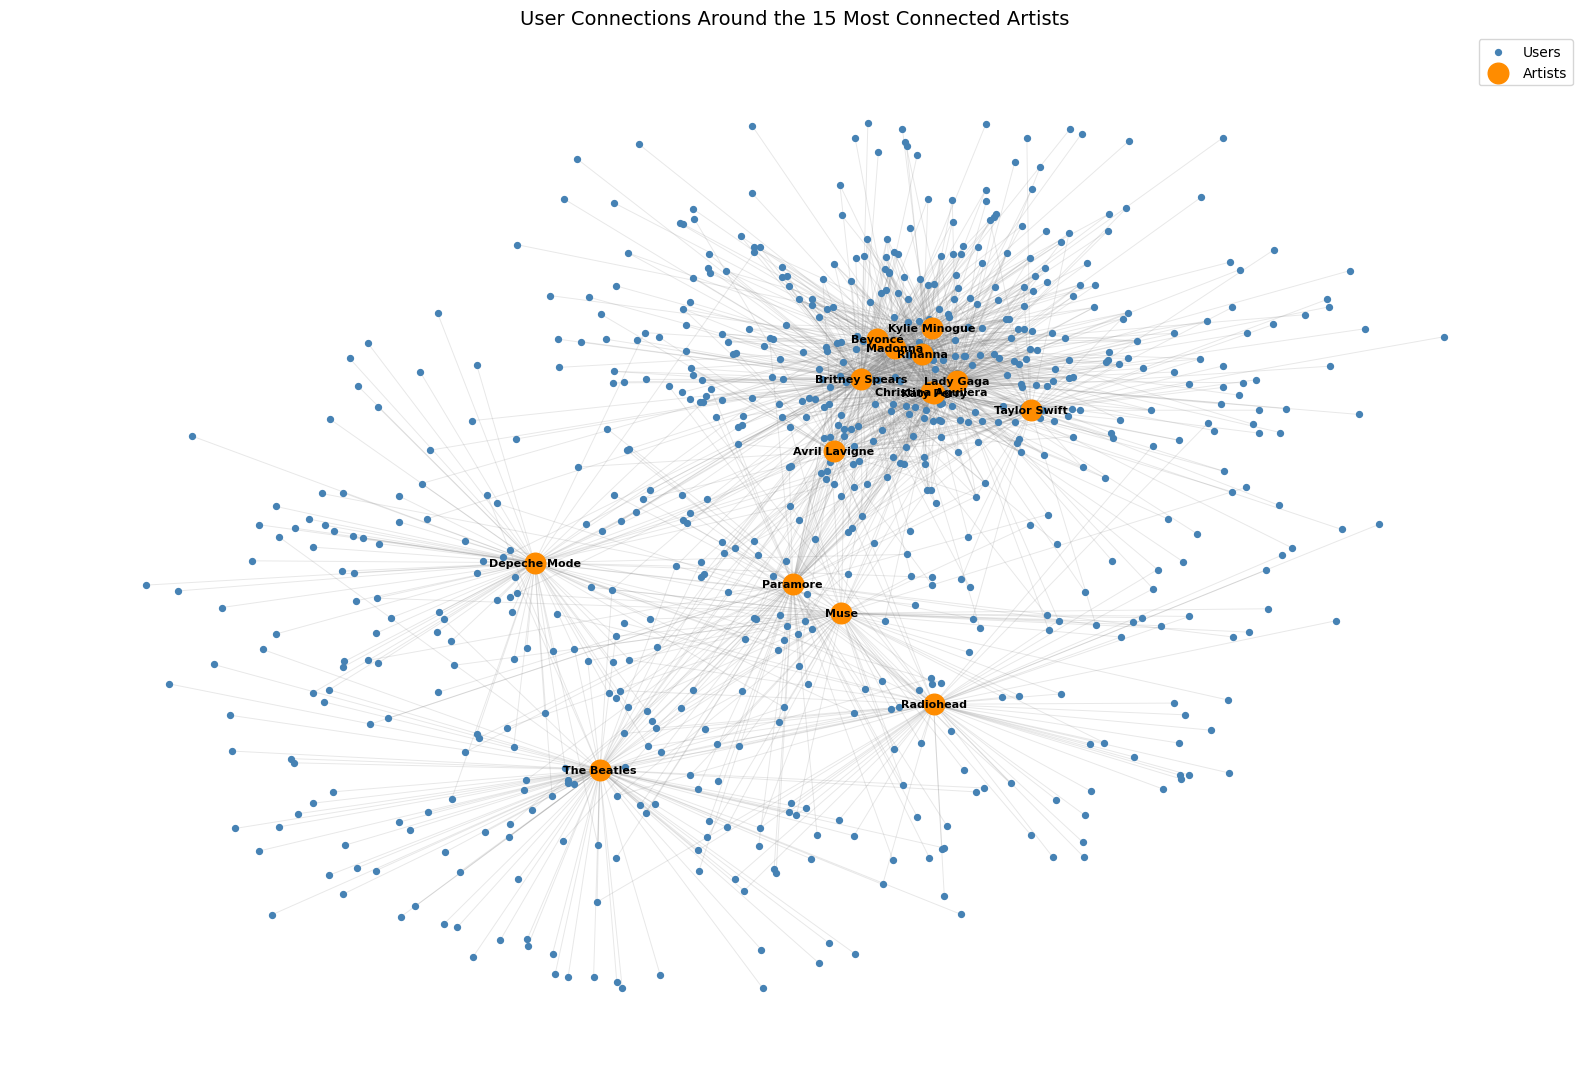

Artists displayed: 15
Users displayed: 700
Total nodes displayed: 715
Total edges displayed: 1569


In [ ]:
# Identify the 15 most connected artists in the largest island
top_artist_nodes = [
    node
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "artist"
]

top_artist_nodes = sorted(
    top_artist_nodes,
    key=lambda node: largest_island.degree(node),
    reverse=True
)[:15]

# Include users connected to at least one of these artists
focused_nodes = set(top_artist_nodes)

for artist in top_artist_nodes:
    focused_nodes.update(largest_island.neighbors(artist))

# Create the focused subnetwork
focused_graph = largest_island.subgraph(focused_nodes).copy()

# Calculate node positions
pos = nx.spring_layout(focused_graph, seed=42, k=0.6)

# Separate users and artists
user_nodes = [
    node for node, data in focused_graph.nodes(data=True)
    if data["node_type"] == "user"
]

artist_nodes = [
    node for node, data in focused_graph.nodes(data=True)
    if data["node_type"] == "artist"
]

# Draw network
plt.figure(figsize=(16, 11))

nx.draw_networkx_edges(
    focused_graph,
    pos,
    alpha=0.18,
    edge_color="gray",
    width=0.7
)

nx.draw_networkx_nodes(
    focused_graph,
    pos,
    nodelist=user_nodes,
    node_color="steelblue",
    node_size=18,
    label="Users"
)

nx.draw_networkx_nodes(
    focused_graph,
    pos,
    nodelist=artist_nodes,
    node_color="darkorange",
    node_size=220,
    label="Artists"
)

# Label only the selected artists
artist_labels = {
    node: focused_graph.nodes[node]["artist_name"]
    for node in artist_nodes
}

nx.draw_networkx_labels(
    focused_graph,
    pos,
    labels=artist_labels,
    font_size=8,
    font_weight="bold"
)

plt.title(
    "User Connections Around the 15 Most Connected Artists",
    fontsize=14
)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Artists displayed:", len(artist_nodes))
print("Users displayed:", len(user_nodes))
print("Total nodes displayed:", focused_graph.number_of_nodes())
print("Total edges displayed:", focused_graph.number_of_edges())

#### Conclusion

This project used the HetRec 2011 Last.fm dataset to investigate the relationships between users and artists through two-mode network analysis. The dataset records user–artist relationships, with listening counts represented as edge weights. By modeling users and artists as two distinct groups of nodes, the network provided a way to examine both the structure of their relationships and the distribution of listening activity. The project aimed to reduce the size of the original network using the island method and determine what the resulting structure reveals about each group.

The island method was applied using a minimum listening-weight threshold of 1,387, removing relationships with lower listening counts. This reduced the network from 19,524 nodes and 92,834 edges to 4,116 nodes and 9,288 edges, representing reductions of approximately 78.9% of the nodes and 90.0% of the edges. The reduced network contained 60 connected components, with the largest island comprising 3,989 nodes and 9,220 edges. This demonstrated that, despite the substantial reduction in network size, most of the retained relationships remained part of one large, interconnected component.

The analysis revealed several patterns within the artist group. Britney Spears had the highest number of user connections in the largest island, with 217, followed by Lady Gaga with 181. Britney Spears also had the highest listening strength, totaling 2,242,053 across her retained connections. Depeche Mode ranked second in listening strength despite having fewer connections than several other leading artists, illustrating that the number of users connected to an artist does not necessarily determine their total listening strength. These findings suggest that artists differ both in their reach among users and in the cumulative listening activity associated with their retained relationships. The results also show that listening activity within the reduced network is concentrated around certain artists rather than being distributed evenly across all artists.

The user analysis revealed differences in both the breadth and intensity of listening behavior. Some users maintained connections with many artists, with the highest observed degree being 50 connections, while others had fewer connections but comparatively high listening strength. For example, user 757 had a listening strength of 469,614 across 17 artist connections, while user 2000 had a similar listening strength of 468,409 across 50 connections. User 2071 also recorded a listening strength of 327,104 across only two connections. These comparisons demonstrate that users differ in the number of artists represented in their retained listening relationships and in the total weight of those relationships. A high listening-strength value can therefore result from a broad set of connections or from substantial listening activity concentrated on a smaller number of artists.

Taken together, the findings show that the two groups play distinct but interconnected roles in the network. Artists vary in the number of users connected to them and the total listening strength of their relationships, while users vary in the breadth and intensity of their connections to artists. The connected-component analysis further demonstrates that the strongest retained relationships form one dominant island, providing a manageable structure for examining these patterns in greater detail.

This project demonstrates how two-mode network analysis and the island method can reduce a large dataset and reveal meaningful structural differences between users and artists. However, the conclusions are limited to relationships retained at the selected threshold of 1,387 listens and should not be generalized to users' complete listening histories or the entire population of music listeners. Listening strength and degree measure recorded activity and connectivity, respectively; neither directly establishes musical preference or personal satisfaction. Despite these limitations, the analysis shows how network reduction can help identify prominent artists, distinguish patterns of user listening behavior, and better understand the structure of relationships between the two groups.